In [1]:
FUND_NAME = "HDFC Large & Mid Cap (Direct-Growth)"
FUND_CODE = 130498   

# Benchmark = EITHER an mfapi scheme code (number) of a Nifty LargeMidcap 250 index fund,
#             OR the file name (text) of an index TRI CSV, e.g. "nifty_largemidcap250_tri.csv"

BENCHMARK = 152889
BENCHMARK_CSV = "nifty_largemidcap250_tri.csv" 
 
PERIODS = {
    "31 Dec 2025 - latest": ("2025-12-31", "latest"),
}

In [2]:
import requests
import pandas as pd

In [3]:
def search_fund(query):
    """Find scheme codes by name, e.g. search_fund('hdfc large and mid cap direct growth')."""
    res = requests.get("https://api.mfapi.in/mf/search", params={"q": query}).json()
    return pd.DataFrame(res)

In [4]:
search_fund('hdfc large and mid cap direct growth')

,schemeCode,schemeName
0,130498,HDFC Large & Mid Cap Fund - Direct Plan - Grow...


In [5]:
search_fund('HDFC Nifty LargeMidcap 250 Index Fund')

,schemeCode,schemeName
0,152889,HDFC NIFTY LargeMidcap 250 Index Fund - Direct...
1,152890,HDFC NIFTY LargeMidcap 250 Index Fund - Regula...


In [6]:
def get_nav(code):
    """Daily NAV history of a scheme from mfapi.in, as a date-indexed Series."""
    data = requests.get(f"https://api.mfapi.in/mf/{code}").json()["data"]
    df = pd.DataFrame(data)
    df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y")
    df["nav"] = df["nav"].astype(float)
    return df.set_index("date")["nav"].sort_index()

In [7]:
def get_series(source):
    """A number -> fund NAV from mfapi.in; a text -> path of an index CSV file."""
    return load_index_series(source) if isinstance(source, str) else get_nav(source)

In [8]:
def load_index_series(path, date_col="Date", value_col=None):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    if value_col is None:
        value_col = "Close" if "Close" in df.columns else df.columns[-1]
    df[date_col] = pd.to_datetime(df[date_col], dayfirst=True)
    s = pd.to_numeric(df[value_col], errors="coerce")
    s.index = df[date_col]
    return s.dropna().sort_index()

In [9]:
def period_return(series, base_date, end_date):
    """
    Total return and annualised return (CAGR) between two dates.
    Uses the last available value on or before each date.
    """
    s = series.loc[:base_date]
    e = series.loc[:end_date]
    years = (e.index[-1] - s.index[-1]).days / 365.25
    total = e.iloc[-1] / s.iloc[-1] - 1
    cagr = (e.iloc[-1] / s.iloc[-1]) ** (1 / years) - 1
    return total, cagr

In [10]:
if FUND_CODE == 0 or BENCHMARK == 0:
    raise SystemExit("Set FUND_CODE and BENCHMARK first. Find codes with: "
                     "print(search_fund('hdfc large and mid cap direct growth')) and "
                     "print(search_fund('hdfc nifty largemidcap 250 index direct growth'))")
 
fund = get_nav(FUND_CODE)
bench = get_series(BENCHMARK)

print("SANITY CHECK: do both ranges cover 14 Oct 2025 to today?")
print(f"  Fund      : {fund.index[0].date()} -> {fund.index[-1].date()}  ({len(fund)} rows)")
print(f"  Benchmark : {bench.index[0].date()} -> {bench.index[-1].date()}  ({len(bench)} rows)\n")

SANITY CHECK: do both ranges cover 14 Oct 2025 to today?
  Fund      : 2014-06-30 -> 2026-10-22  (3029 rows)
  Benchmark : 2024-10-09 -> 2026-10-22  (502 rows)



In [11]:
latest = min(fund.index[-1], bench.index[-1])
rows = []
step1_out = {}
for regime, (base, end) in PERIODS.items():
    base = pd.Timestamp(base)
    end = latest if end == "latest" else pd.Timestamp(end)
 
    if fund.index[0] > base or bench.index[0] > base:
        print(f"Skipping '{regime}': data starts after {base.date()}")
        continue
 
    f_tot, f_cagr = period_return(fund, base, end)
    b_tot, b_cagr = period_return(bench, base, end)
    rows.append({
        "Period": regime,"Period end": end.date(),
        "Fund total": f_tot, "Bench total": b_tot, "Active (total)": f_tot - b_tot,
        "Fund CAGR": f_cagr, "Bench CAGR": b_cagr, "Active CAGR": f_cagr - b_cagr,
    })
    step1_out[regime] = {
        "base_date": str(base.date()), "end_date": str(end.date()),
        "fund_total": f_tot, "bench_total": b_tot, "active_total": f_tot - b_tot,
        "fund_cagr": f_cagr, "bench_cagr": b_cagr, "active_cagr": f_cagr - b_cagr,
    }

In [12]:
result = pd.DataFrame(rows).set_index("Period")
pct_cols = [c for c in result.columns if c != "Period end"]
result[pct_cols] = (result[pct_cols] * 100).round(2)
 
print(f"{FUND_NAME}: returns in %")
print(result.to_string())

HDFC Large & Mid Cap (Direct-Growth): returns in %
                      Period end  Fund total  Bench total  Active (total)  Fund CAGR  Bench CAGR  Active CAGR
Period                                                                                                       
31 Dec 2025 - latest  2026-10-22       -7.08        -8.02            0.94       -8.7       -9.84         1.14


In [13]:
# Reusable variables for Step 3 (decimals, first period) + saved file
_first = next(iter(step1_out.values()))
ACTIVE_TOTAL, BENCH_TOTAL, FUND_TOTAL = _first["active_total"], _first["bench_total"], _first["fund_total"]
BASE_DATE, END_DATE = _first["base_date"], _first["end_date"]

pd.DataFrame(step1_out).T.rename_axis("Period").to_csv("step1_results.csv")

In [14]:
SNAPSHOTS = [
    ("2025-12-31", "fund_sector_weights_dec2025.csv", "bench_sector_weights_dec2025.csv"),
    ("2026-09-30", "fund_sector_weights_sep2026.csv", "bench_sector_weights_sep2026.csv")
]

DROP_SECTORS = ["Units issued by ReIT (Equity & Other Equity Instrument)"]
 
SHIFT_FLAG = 5.0   # flag a sector if the fund's weight moved by more than this (% points) between snapshots

In [15]:
def load_weights(path, normalise=True):
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    df["sector"] = df["sector"].astype(str).str.strip()
    df = df[~df["sector"].isin(DROP_SECTORS)]
    w = df.groupby("sector")["weight"].sum()
 
    raw_total = w.sum()
    print(f"{path}: {len(w)} sectors, adds up to {raw_total:.2f}%")
    if normalise:
        w = w / raw_total * 100
    return w

In [16]:
def time_weighted_average(snapshots, dates):
    total = 0
    days_sum = 0
    for i in range(len(dates) - 1):
        days = (pd.Timestamp(dates[i + 1]) - pd.Timestamp(dates[i])).days
        stretch_avg = (snapshots.iloc[:, i] + snapshots.iloc[:, i + 1]) / 2
        total = total + stretch_avg * days
        days_sum += days
    return total / days_sum

In [17]:
dates = [d for d, _, _ in SNAPSHOTS]
labels = [pd.Timestamp(d).strftime("%b %Y") for d in dates]
 
fund_cols, bench_cols = {}, {}
for d, label, (_, f_path, b_path) in zip(dates, labels, SNAPSHOTS):
    fund_cols[label] = load_weights(f_path)
    bench_cols[label] = load_weights(b_path)
print()

fund_sector_weights_dec2025.csv: 42 sectors, adds up to 98.79%
bench_sector_weights_dec2025.csv: 45 sectors, adds up to 99.89%
fund_sector_weights_sep2026.csv: 43 sectors, adds up to 98.95%
bench_sector_weights_sep2026.csv: 45 sectors, adds up to 98.69%



In [32]:
fund_w = pd.DataFrame(fund_cols)
bench_w = pd.DataFrame(bench_cols)

In [33]:
all_sectors = fund_w.index.union(bench_w.index)
fund_w, bench_w = fund_w.reindex(all_sectors), bench_w.reindex(all_sectors)
missing = pd.concat({"Fund": fund_w, "Bench": bench_w}, axis=1)
missing = missing[missing.isna().any(axis=1)]
if len(missing):
    print("CHECK: these sectors are missing from at least one snapshot (spelling mismatch or real change?):")
    print(missing.round(2).to_string(), "\n")
fund_w, bench_w = fund_w.fillna(0), bench_w.fillna(0)

CHECK: these sectors are missing from at least one snapshot (spelling mismatch or real change?):
                                      Fund             Bench         
                                  Dec 2025 Sep 2026 Dec 2025 Sep 2026
sector                                                               
Cigarettes & Tobacco Products          NaN     0.29     0.15     0.10
Commercial Services & Supplies        0.48     0.64      NaN      NaN
Consumable Fuels                       NaN      NaN     0.32     0.40
Diversified                            NaN      NaN     0.19     0.06
Diversified Metals                     NaN      NaN     0.36     0.17
Entertainment                         0.40     0.37      NaN      NaN
Metals & Minerals Trading              NaN      NaN     0.20     0.39
Minerals & Mining                      NaN      NaN     0.59     0.65
Telecom - Equipment & Accessories     0.12     0.52      NaN      NaN 



In [34]:
table = pd.DataFrame({
    "Fund first": fund_w.iloc[:, 0], "Fund last": fund_w.iloc[:, -1],
    "Fund avg": time_weighted_average(fund_w, dates),
    "Bench avg": time_weighted_average(bench_w, dates),
})
table["Active weight"] = table["Fund avg"] - table["Bench avg"]
table["Fund change"] = table["Fund last"] - table["Fund first"]
table["Biggest step"] = fund_w.diff(axis=1).abs().max(axis=1)     # largest move between two snapshots
table = table.sort_values("Active weight", ascending=False)

In [21]:
show = ["Fund avg", "Bench avg", "Active weight",] #"Fund change"]
print(f"SECTOR ACTIVE WEIGHTS (% points; positive = overweight), snapshots: {', '.join(labels)}")
print(table[show].round(2).to_string(), "\n")
 
print("Biggest overweights :", ", ".join(f"{s} ({v:+.2f})" for s, v in table["Active weight"].head(3).items()))
print("Biggest underweights:", ", ".join(f"{s} ({v:+.2f})" for s, v in table["Active weight"].tail(3).items()))
print(f"Total active weight (should be about 0): {table['Active weight'].sum():.2f}\n")
 
big = table[table["Biggest step"] > SHIFT_FLAG]
if len(big):
    print(f"FLAG: fund weight moved by more than {SHIFT_FLAG} points between two snapshots in:")
    print(big[["Fund first", "Fund last", "Biggest step"]].round(2).to_string())
else:
    print(f"No sector moved by more than {SHIFT_FLAG} points between snapshots, so averaging looks reasonable.")
 
out_name ="active_weights.csv"
table.to_csv(out_name)      # saved for Step 3
print(f"\nSaved: {out_name}")

SECTOR ACTIVE WEIGHTS (% points; positive = overweight), snapshots: Dec 2025, Sep 2026
                                                  Fund avg  Bench avg  Active weight
sector                                                                              
Pharmaceuticals & Biotechnology                      10.66       5.88           4.78
Finance                                               8.24       6.36           1.88
Auto Components                                       4.27       2.95           1.32
Insurance                                             3.33       2.19           1.15
Chemicals & Petrochemicals                            2.41       1.28           1.13
Healthcare Services                                   2.52       1.53           0.99
Agricultural, Commercial & Construction Vehicles      1.90       0.91           0.99
Transport Services                                    1.46       0.63           0.83
Industrial Manufacturing                              0.91     

In [22]:
SECTOR_TO_INDEX = {
    "Banks": "Nifty Bank",
    "Finance": "Nifty Financial Services Ex-Bank",
    "Insurance": "Nifty Financial Services Ex-Bank",
    "Capital Markets": "Nifty Capital Markets",
    "IT - Software": "Nifty IT",
    "IT - Services": "Nifty IT",
    "Pharmaceuticals & Biotechnology": "Nifty Pharma",
    "Healthcare Services": "Nifty Healthcare",
    "Automobiles": "Nifty Auto",
    "Auto Components": "Nifty Auto",
    "Agricultural, Commercial & Construction Vehicles": "Nifty Auto",
    "Diversified Fmcg": "Nifty FMCG",
    "Personal Products": "Nifty FMCG",
    "Food Products": "Nifty FMCG",
    "Agricultural Food & Other Products": "Nifty FMCG",
    "Beverages": "Nifty FMCG",
    "Cigarettes & Tobacco Products": "Nifty FMCG",
    "Petroleum Products": "Nifty Oil & Gas",
    "Oil": "Nifty Oil & Gas",
    "Gas": "Nifty Oil & Gas",
    "Consumable Fuels": "Nifty Oil & Gas",
    "Power": "Nifty Energy",
    "Ferrous Metals": "Nifty Metal",
    "Non - Ferrous Metals": "Nifty Metal",
    "Minerals & Mining": "Nifty Metal",
    "Diversified Metals": "Nifty Metal",
    "Metals & Minerals Trading": "Nifty Metal",
    "Consumer Durables": "Nifty Consumer Durables",
    "Realty": "Nifty Realty",
    "Cement & Cement Products": "Nifty Cement",
    "Chemicals & Petrochemicals": "Nifty Chemicals",
    "Entertainment": "Nifty Media",
    "Leisure Services": "Nifty India Tourism",
    "Construction": "Nifty Infrastructure",
    "Transport Infrastructure": "Nifty Infrastructure",
    "Transport Services": "Nifty Transportation & Logistics",
    "Electrical Equipment": "Nifty India Manufacturing",
    "Industrial Products": "Nifty India Manufacturing",
    "Industrial Manufacturing": "Nifty India Manufacturing",
    "Aerospace & Defense": "Nifty India Defence",
}

In [23]:
pip install jugaad-data

Note: you may need to restart the kernel to use updated packages.


In [24]:
import time
from datetime import date
import pandas as pd
from jugaad_data.nse import index_df

INDICES = [
    "Nifty Bank",
    "Nifty Financial Services Ex-Bank",
    "Nifty Capital Markets",
    "Nifty IT",
    "Nifty Pharma",
    "Nifty Healthcare",
    "Nifty Auto",
    "Nifty FMCG",
    "Nifty Oil & Gas",
    "Nifty Energy",
    "Nifty Metal",
    "Nifty Consumer Durables",
    "Nifty Realty",
    "Nifty Cement",
    "Nifty Chemicals",
    "Nifty Media",
    "Nifty Infrastructure",
    "Nifty India Manufacturing",
    "Nifty India Defence",
    "Nifty India Tourism",
    "Nifty Transportation & Logistics",
]

START = date(2025,12,31)
END = date.today()

frames, failed = [], []

for name in INDICES:
    for attempt in range(3):                       # simple retry
        try:
            df = index_df(symbol=name.upper(), from_date=START, to_date=END)
            if df is None or df.empty:
                raise ValueError("empty result")
            df["Index"] = name
            frames.append(df)
            print(f"OK   {name}: {len(df)} rows")
            break
        except Exception as e:
            if attempt == 2:
                failed.append((name, str(e)))
                print(f"FAIL {name}: {e}")
            time.sleep(2)
    time.sleep(1)                                   # be polite to the server

raw = pd.concat(frames, ignore_index=True)

# Keep only date, open, close (column names may vary slightly by library version)
cols = {c.lower(): c for c in raw.columns}
date_col  = cols.get("historicaldate") or cols.get("date")
open_col  = cols["open"]
close_col = cols["close"]

out = raw[["Index", date_col, open_col, close_col]].copy()
out.columns = ["Index", "Date", "Open", "Close"]
out["Date"] = pd.to_datetime(out["Date"], format="mixed", dayfirst=True)
out[["Open", "Close"]] = out[["Open", "Close"]].apply(pd.to_numeric, errors="coerce")
out = out.sort_values(["Index", "Date"]).reset_index(drop=True)

out.to_csv("nse_sectoral_open_close_2026.csv", index=False)
print("\nFailed:", failed)

OK   Nifty Bank: 200 rows
OK   Nifty Financial Services Ex-Bank: 200 rows
OK   Nifty Capital Markets: 200 rows
OK   Nifty IT: 200 rows
OK   Nifty Pharma: 200 rows
OK   Nifty Healthcare: 200 rows
OK   Nifty Auto: 200 rows
OK   Nifty FMCG: 200 rows
OK   Nifty Oil & Gas: 200 rows
OK   Nifty Energy: 200 rows
OK   Nifty Metal: 200 rows
OK   Nifty Consumer Durables: 200 rows
OK   Nifty Realty: 200 rows
OK   Nifty Cement: 200 rows
OK   Nifty Chemicals: 200 rows
OK   Nifty Media: 200 rows
OK   Nifty Infrastructure: 200 rows
OK   Nifty India Manufacturing: 200 rows
OK   Nifty India Defence: 200 rows
OK   Nifty India Tourism: 200 rows
OK   Nifty Transportation & Logistics: 200 rows

Failed: []


In [25]:
STEP1_FILE = "step1_results.csv"
WEIGHTS_FILE = "active_weights.csv"
SECTOR_INDEX_FILE = "nse_sectoral_open_close_2026.csv"
PERIOD = None          # None = first period in Step 1's results, or type its name e.g. "14 Oct 2025 - latest"

In [26]:
step1 = pd.read_csv(STEP1_FILE, index_col="Period")
period = PERIOD or step1.index[0]
p = step1.loc[period]
 
BASE_DATE = pd.Timestamp(p["base_date"])
END_DATE = pd.Timestamp(p["end_date"])
FUND_TOTAL = float(p["fund_total"])          # decimals: 0.05 = 5%
BENCH_TOTAL = float(p["bench_total"])
ACTIVE_TOTAL = float(p["active_total"])      # fund total - benchmark total
 
print(f"Period: {period}  ({BASE_DATE.date()} -> {END_DATE.date()})")
print(f"Fund {FUND_TOTAL*100:.2f}%  |  Benchmark {BENCH_TOTAL*100:.2f}%  |  Active return {ACTIVE_TOTAL*100:+.2f}%\n")

Period: 31 Dec 2025 - latest  (2025-12-31 -> 2026-10-22)
Fund -7.08%  |  Benchmark -8.02%  |  Active return +0.94%



In [27]:
# %% 3. SECTOR INDEX RETURNS OVER THE SAME PERIOD
px = pd.read_csv(SECTOR_INDEX_FILE, parse_dates=["Date"])
close = px.pivot(index="Date", columns="Index", values="Close").sort_index().ffill()
 
if close.index[0] > BASE_DATE:
    raise SystemExit(f"Sector index data starts {close.index[0].date()}, after the base date "
                     f"{BASE_DATE.date()}. Re-run the jugaad-data script with an earlier start date.")
 
# last available close on or before each date (same rule as Step 1)
index_return = close.loc[:END_DATE].iloc[-1] / close.loc[:BASE_DATE].iloc[-1] - 1

In [28]:
# %% 4. ALLOCATION EFFECT BY SECTOR
w = pd.read_csv(WEIGHTS_FILE, index_col=0)
w[["Fund avg", "Bench avg", "Active weight"]] /= 100        # % -> decimals
 
w["Index used"] = w.index.map(SECTOR_TO_INDEX)
w["Sector return"] = w["Index used"].map(index_return)
 
neutral = w["Sector return"].isna()
if neutral.any():
    print("WARNING: no index return for these sectors (treated as neutral, zero effect):")
    print(w.loc[neutral, ["Fund avg", "Bench avg", "Index used"]].mul([100, 100, 1]).round(2).to_string(), "\n")
w["Sector return"] = w["Sector return"].fillna(BENCH_TOTAL)
 
w["Relative return"] = w["Sector return"] - BENCH_TOTAL
w["Allocation effect"] = w["Active weight"] * w["Relative return"]
w = w.sort_values("Allocation effect", ascending=False)
 
ALLOCATION_TOTAL = w["Allocation effect"].sum()
OTHER = ACTIVE_TOTAL - ALLOCATION_TOTAL                     # selection + interaction + other

                                   Fund avg  Bench avg Index used
sector                                                           
Commercial Services & Supplies         0.56       0.00        NaN
Telecom - Equipment & Accessories      0.32       0.00        NaN
Fertilizers & Agrochemicals            1.17       1.14        NaN
Retailing                              3.55       3.61        NaN
Diversified                            0.00       0.13        NaN
Textiles & Apparels                    0.19       0.43        NaN
Telecom - Services                     2.70       3.40        NaN
Financial Technology (Fintech)         0.49       1.42        NaN 



In [29]:
# %% 5. RESULTS
show = w[["Fund avg", "Bench avg", "Active weight", "Sector return", "Relative return", "Allocation effect"]] * 100
print("ALLOCATION EFFECT BY SECTOR (% / % points)")
print(show.round(2).to_string(), "\n")
 
print("Biggest helpers  :", ", ".join(f"{s} ({v*100:+.2f})" for s, v in w["Allocation effect"].head(3).items()))
print("Biggest detractors:", ", ".join(f"{s} ({v*100:+.2f})" for s, v in w["Allocation effect"].tail(3).items()))
 
print("\nBREAKDOWN OF ACTIVE RETURN (% points)")
print(f"  Active return (Step 1)                         : {ACTIVE_TOTAL*100:+.2f}")
print(f"  Allocation effect (sector weights vs benchmark): {ALLOCATION_TOTAL*100:+.2f}")
print(f"  Everything else (selection, interaction, etc.) : {OTHER*100:+.2f}")
if abs(ACTIVE_TOTAL) > 1e-9:
    print(f"  Allocation explains {ALLOCATION_TOTAL / ACTIVE_TOTAL * 100:.0f}% of the active return")
 
coverage = 1 - w.loc[neutral, "Fund avg"].sum() / w["Fund avg"].sum()
print(f"\nSector index coverage of fund weight: {coverage*100:.0f}%  (lower = less reliable)")
print(f"Active weights add up to {w['Active weight'].sum()*100:.2f} points (should be about 0)")
 
w.to_csv("allocation_effect.csv")

ALLOCATION EFFECT BY SECTOR (% / % points)
                                                  Fund avg  Bench avg  Active weight  Sector return  Relative return  Allocation effect
sector                                                                                                                                 
Pharmaceuticals & Biotechnology                      10.66       5.88           4.78          12.64            20.67               0.99
Healthcare Services                                   2.52       1.53           0.99           5.98            14.00               0.14
Diversified Fmcg                                      0.92       1.86          -0.94         -22.30           -14.27               0.13
Petroleum Products                                    2.75       4.39          -1.64         -14.60            -6.57               0.11
Aerospace & Defense                                   1.48       0.99           0.49          13.45            21.48               0.11
Agric

In [35]:

"""RISK SECTION (simplified): did the fund take more risk than its benchmark to earn its active return?

Five measures, over exactly the same period and from the same Step 1 results as the return section:
  1. Volatility        how bumpy the ride was           (fund and benchmark)
  2. Max drawdown      the worst peak-to-trough fall    (fund and benchmark)
  3. Beta              how much the fund moves when the benchmark moves 1%
  4. Tracking error    how far the fund strays from the benchmark
  5. Information ratio active return earned per unit of tracking error
"""

# %% 1. SETTINGS
import numpy as np
import matplotlib.pyplot as plt
 
TRADING_DAYS = 252
STEP1_FILE = "step1_results.csv"       # saved by Step 1: the single source for the period and the returns
 
 
# %% 2. THE PERIOD AND THE RETURNS, TAKEN FROM STEP 1
# Reading them from Step 1's own file means the risk section cannot disagree with the return section.
s1 = pd.read_csv(STEP1_FILE, index_col="Period")
risk_period = s1.index[0]                                  # the first period, same as Step 3 uses
s1p = s1.loc[risk_period]
 
r_base = pd.Timestamp(s1p["base_date"])                    # day before the period starts
r_end = pd.Timestamp(s1p["end_date"])                      # the end date Step 1 used
r_fund_total = float(s1p["fund_total"])                    # decimals: 0.05 = 5%
r_bench_total = float(s1p["bench_total"])
r_active_cagr = float(s1p["active_cagr"])
 
print(f"Period: {risk_period}  ({r_base.date()} -> {r_end.date()})")
 
 
# %% 3. THE PRICES FOR THAT PERIOD
# Best case: use Step 1's own downloads (`fund` and `bench` are still price series, so the data is identical).
# If an older Step 2 overwrote them with weight tables, download the prices again instead.
if isinstance(fund, pd.Series) and isinstance(bench, pd.Series):
    nav_source = {"Fund": fund, "Benchmark": bench}
    print("Using Step 1's price data (no new download).")
else:
    nav_source = {"Fund": get_nav(FUND_CODE), "Benchmark": get_series(BENCHMARK)}
    print("Step 1's prices were overwritten; downloaded them again and cut them to Step 1's dates.")
nav_all = pd.concat(nav_source, axis=1, join="inner").dropna()
base_day = nav_all.loc[:r_base].index[-1]                  # last price on or before the base date (same rule as Step 1)
nav = nav_all.loc[base_day:r_end]
 
if nav.index[-1] != r_end:
    print(f"WARNING: no common price on Step 1's end date {r_end.date()}; the last one used is {nav.index[-1].date()}.")
 
# Consistency check against the return section
chk_fund = nav["Fund"].iloc[-1] / nav["Fund"].iloc[0] - 1
chk_bench = nav["Benchmark"].iloc[-1] / nav["Benchmark"].iloc[0] - 1
if abs(chk_fund - r_fund_total) > 1e-4 or abs(chk_bench - r_bench_total) > 1e-4:
    print("WARNING: returns in this window do not match Step 1.")
    print(f"  Fund      here {chk_fund:.2%}  vs Step 1 {r_fund_total:.2%}")
    print(f"  Benchmark here {chk_bench:.2%}  vs Step 1 {r_bench_total:.2%}")
    print("  Re-run Step 1 (cells that download the prices) and then this section.")
else:
    print(f"Check passed: fund {chk_fund:.2%} and benchmark {chk_bench:.2%} match Step 1.")
 
years = (nav.index[-1] - nav.index[0]).days / 365.25
print(f"{len(nav) - 1} daily returns over {years:.2f} years\n")
 
 
# %% 4. THE FIVE MEASURES
daily = nav.pct_change().dropna()                          # daily returns of the fund and the benchmark
ann = np.sqrt(TRADING_DAYS)
 
volatility = daily.std(ddof=1) * ann * 100                                      # % per year
max_drawdown = (nav / nav.cummax() - 1).min() * 100                             # %, worst fall from a previous peak
beta = daily["Fund"].cov(daily["Benchmark"]) / daily["Benchmark"].var(ddof=1)
tracking_error = (daily["Fund"] - daily["Benchmark"]).std(ddof=1) * ann * 100   # % per year
active_cagr = r_active_cagr * 100                                               # % per year, straight from Step 1
info_ratio = active_cagr / tracking_error
 
absolute = pd.DataFrame({"Fund": [volatility["Fund"], max_drawdown["Fund"]],
                         "Benchmark": [volatility["Benchmark"], max_drawdown["Benchmark"]]},
                        index=["Volatility (% p.a.)", "Max drawdown (%)"])
relative = pd.Series({"Beta": beta,
                      "Tracking error (% p.a.)": tracking_error,
                      "Active return, CAGR (% p.a., from Step 1)": active_cagr,
                      "Information ratio": info_ratio}, name="Fund vs Benchmark")
 
 
# %% 5. RESULTS
print(f"RISK: {FUND_NAME} vs benchmark, {r_base.date()} -> {r_end.date()}")
print(absolute.round(2).to_string(), "\n")
print(relative.round(2).to_string(), "\n")
 
print("In plain words:")
more_less = "more" if volatility["Fund"] > volatility["Benchmark"] else "less"
print(f"  - The fund was {more_less} volatile than the benchmark ({volatility['Fund']:.1f}% vs {volatility['Benchmark']:.1f}% a year).")
print(f"  - Its worst fall was {max_drawdown['Fund']:.1f}%, against {max_drawdown['Benchmark']:.1f}% for the benchmark.")
print(f"  - Beta {beta:.2f}: when the benchmark moves 1%, the fund tends to move {beta:.2f}%.")
print(f"  - Tracking error {tracking_error:.1f}%: the fund's returns typically stray this far from the benchmark's each year.")
print(f"  - Information ratio {info_ratio:.2f}: {active_cagr:+.2f}% a year of active return for {tracking_error:.1f}% of tracking error"
      f" ({'paid for the deviation' if info_ratio > 0 else 'not paid for the deviation'}).")
if years < 1:
    print("\nNOTE: the period is under one year, so the annualised figures (active return, information ratio) are noisy.")
 
absolute.to_csv("risk_absolute.csv")
relative.to_csv("risk_relative.csv")
 

Period: 31 Dec 2025 - latest  (2025-12-31 -> 2026-10-22)
Step 1's prices were overwritten; downloaded them again and cut them to Step 1's dates.
Check passed: fund -7.08% and benchmark -8.02% match Step 1.
199 daily returns over 0.81 years

RISK: HDFC Large & Mid Cap (Direct-Growth) vs benchmark, 2025-12-31 -> 2026-10-22
                      Fund  Benchmark
Volatility (% p.a.)  16.22      15.99
Max drawdown (%)    -15.08     -14.41 

Beta                                         1.01
Tracking error (% p.a.)                      2.19
Active return, CAGR (% p.a., from Step 1)    1.14
Information ratio                            0.52 

In plain words:
  - The fund was more volatile than the benchmark (16.2% vs 16.0% a year).
  - Its worst fall was -15.1%, against -14.4% for the benchmark.
  - Beta 1.01: when the benchmark moves 1%, the fund tends to move 1.01%.
  - Tracking error 2.2%: the fund's returns typically stray this far from the benchmark's each year.
  - Information ratio 0.52: 

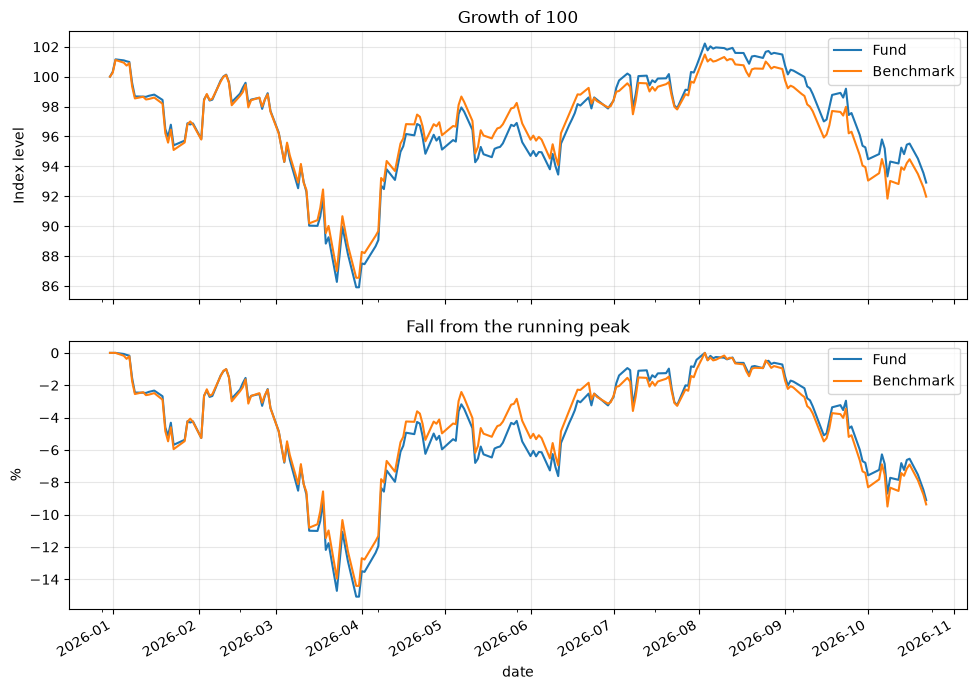

In [31]:
# %% 6. TWO SIMPLE CHARTS
growth = nav / nav.iloc[0] * 100
drawdown = (nav / nav.cummax() - 1) * 100

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
growth.plot(ax=ax[0]);    ax[0].set_title("Growth of 100");              ax[0].set_ylabel("Index level")
drawdown.plot(ax=ax[1]);  ax[1].set_title("Fall from the running peak"); ax[1].set_ylabel("%")
for a_ in ax:
    a_.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("risk_charts.png", dpi=150)
plt.show()